<a href="https://colab.research.google.com/github/Elli3e/4GeeksAcademy/blob/master/image_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [24]:
import os
os.listdir("/content/drive/MyDrive/dogs-vs-cats/training")

['cats', 'dogs']

In [10]:
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

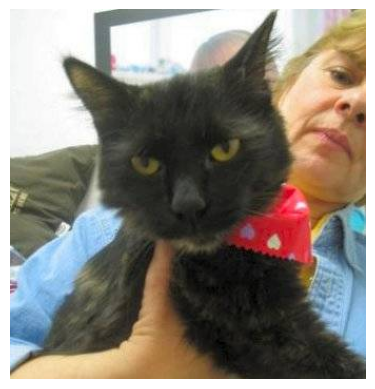

In [11]:
img = Image.open("/content/drive/MyDrive/dogs-vs-cats/training/cats/cat.2500.jpg")

plt.imshow(img)
plt.axis("off")
plt.show()

In [12]:
import tensorflow as tf

data = tf.keras.utils.image_dataset_from_directory("/content/drive/MyDrive/dogs-vs-cats/training",
    image_size=(224, 224),
    batch_size=18,
    shuffle=False
)

Found 20000 files belonging to 2 classes.


In [13]:
print(type(data))
print(data)

<class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'>
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


In [14]:
print(os.listdir("/content/drive/MyDrive/dogs-vs-cats/training/dogs")[:20])

['dog.6621.jpg', 'dog.8624.jpg', 'dog.4988.jpg', 'dog.11723.jpg', 'dog.11079.jpg', 'dog.9248.jpg', 'dog.4778.jpg', 'dog.12202.jpg', 'dog.3759.jpg', 'dog.4022.jpg', 'dog.10415.jpg', 'dog.7517.jpg', 'dog.5314.jpg', 'dog.8156.jpg', 'dog.3003.jpg', 'dog.6635.jpg', 'dog.9937.jpg', 'dog.7265.jpg', 'dog.7271.jpg', 'dog.12216.jpg']


Found 10000 files.


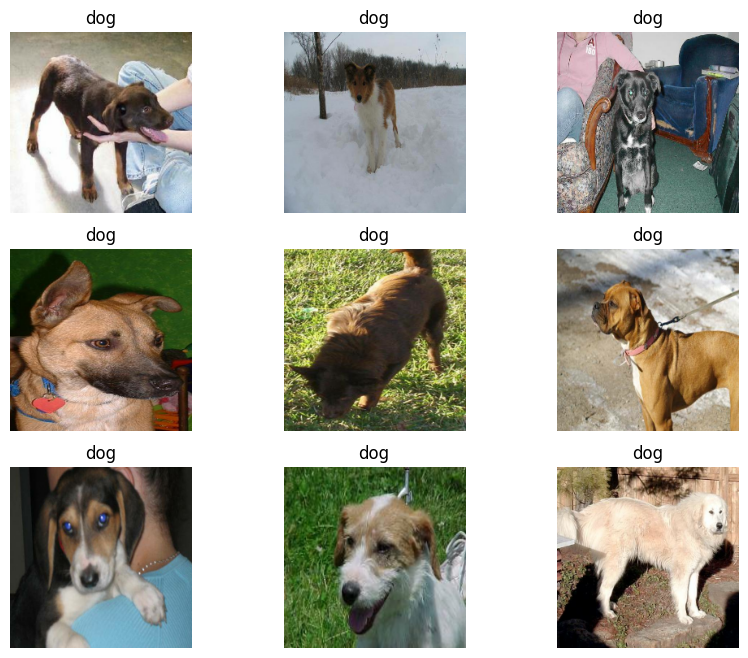

In [15]:
dog_img= tf.keras.utils.image_dataset_from_directory("/content/drive/MyDrive/dogs-vs-cats/training/dogs", labels=None,
    batch_size=9,
    image_size=(224, 224))

fig, ax = plt.subplots(3,3, figsize = (10, 8))
for images in dog_img.take(1):
    for i in range(9):
        ax[i//3, i%3].imshow(images[i].numpy().astype("uint8"))
        ax[i//3, i%3].axis("off")
        ax[i//3, i%3].set_title("dog")

plt.show()


Found 10000 files.


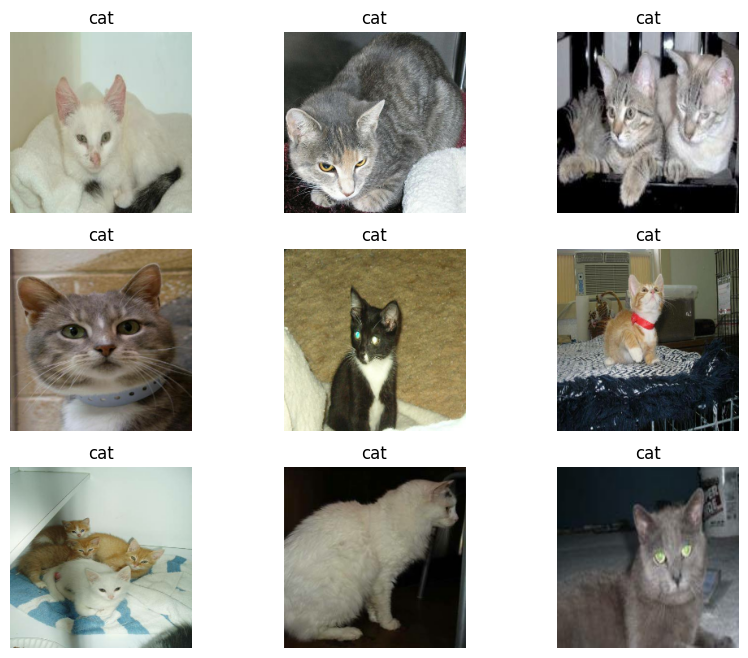

In [16]:
cat_img= tf.keras.utils.image_dataset_from_directory("/content/drive/MyDrive/dogs-vs-cats/training/cats",
                                                     labels=None,
                                                     image_size=(224, 224),
                                                     batch_size=9)

fig, ax = plt.subplots(3,3, figsize=(10, 8))

for cat in cat_img.take(1):
  for i in range(9):
    ax[i//3, i%3].imshow(cat[i].numpy().astype("uint8"))
    ax[i//3, i%3].set_title("cat")
    ax[i//3, i%3].axis("off")

plt.show()




In [17]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

imagegen =ImageDataGenerator(rescale =1/255)

train_generator = imagegen.flow_from_directory("/content/drive/MyDrive/dogs-vs-cats/training", target_size=(224, 224), class_mode="binary")

val_generator= imagegen.flow_from_directory("/content/drive/MyDrive/dogs-vs-cats/validation", target_size =(224, 224), class_mode= "binary")

test_generator = imagegen.flow_from_directory("/content/drive/MyDrive/dogs-vs-cats/testing", target_size =(224, 224), class_mode="binary", shuffle=False)



Found 20000 images belonging to 2 classes.
Found 2500 images belonging to 2 classes.
Found 2500 images belonging to 2 classes.


In [18]:
from keras.models import Sequential
from keras.layers import Dense, GlobalAveragePooling2D
from keras.applications import EfficientNetB0

model = Sequential()
model.add(EfficientNetB0(include_top = False, weights = None, input_shape = (224, 224, 3)))
model.add(GlobalAveragePooling2D())
model.add(Dense(units = 128, activation = "relu"))
model.add(Dense(units = 1, activation = "sigmoid"))


In [19]:
from keras.optimizers import Adam

model.compile(optimizer= Adam(learning_rate= 0.001), loss= "binary_crossentropy", metrics= ["accuracy"])

In [25]:
from keras.callbacks import ModelCheckpoint, EarlyStopping

def fit_generator():

  Checkpoint= ModelCheckpoint("best_model.keras", monitor="val_accuracy",save_best_only=True, mode="max", save_weights_only=False, verbose=1)

  early_stop = EarlyStopping(monitor="val_accuracy",patience=3, restore_best_weights=True)

  return [Checkpoint, early_stop]

history = model.fit(train_generator, validation_data=val_generator, epochs=10, callbacks=fit_generator())

test_loss, test_accuracy = model.evaluate(test_generator)

print("Test accuracy:", test_accuracy)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - accuracy: 0.6383 - loss: 0.6439 
Epoch 1: val_accuracy improved from None to 0.58360, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
625/625 ━━━━━━━━━━━━━━━━━━━━ 7674s 12s/step - accuracy: 0.6775 - loss: 0.6015 - val_accuracy: 0.5836 - val_loss: 0.8880
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: 0.7671 - loss: 0.4855
Epoch 2: val_accuracy improved from 0.58360 to 0.77840, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
625/625 ━━━━━━━━━━━━━━━━━━━━ 90s 144ms/step - accuracy: 0.7821 - loss: 0.4631 - val_accuracy: 0.7784 - val_loss: 0.4791
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.8315 - loss: 0.3827
Epoch 3: val_accuracy improved from 0.77840 to 0.84920, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
625/625 ━━━━━━━━━━━━━━━━━━━━ 95s 151ms/step - accuracy: 0.8346 - loss: 0.3708

In [26]:
predictions = model.predict(test_generator)

from sklearn.metrics import classification_report

y_pred = (predictions > 0.5).astype(int).reshape(-1, )

y_test = test_generator.classes

print(classification_report(y_test, y_pred))

79/79 ━━━━━━━━━━━━━━━━━━━━ 22s 187ms/step
              precision    recall  f1-score   support

           0       0.88      0.91      0.90      1250
           1       0.91      0.88      0.89      1250

    accuracy                           0.90      2500
   macro avg       0.90      0.90      0.90      2500
weighted avg       0.90      0.90      0.90      2500



In [27]:

model = tf.keras.models.load_model("best_model.keras")

converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open("model.tflite", "wb") as f:
    f.write(tflite_model)

Saved artifact at '/tmp/tmpo2fvt32j'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139535400747088: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139535400748048: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139535400753616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139535400754000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139535400753808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139535400754768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139535400754192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139535400753040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139535400754960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139535400754384: TensorSpec(shape=(), dtype=tf.resource, name=Non

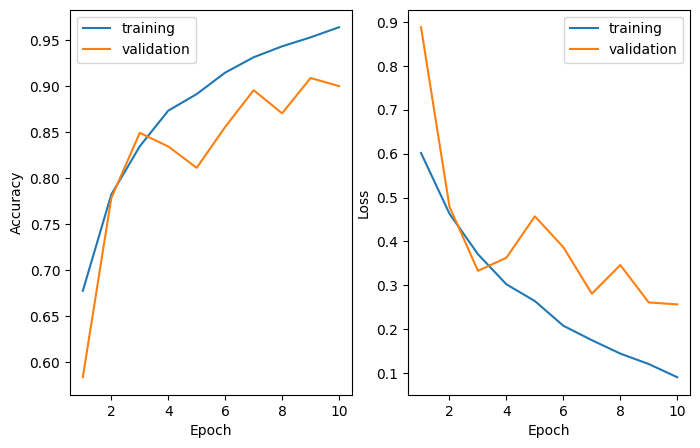

In [30]:


fig, ax = plt.subplots(1,2, figsize=(8,5))

epoch = np.arange(1, len(history.history["accuracy"])+1)

accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss=history.history["val_loss"]


ax[0].plot(epoch, accuracy, label="training")
ax[0].plot(epoch, val_accuracy, label="validation")
ax[0].set_ylabel("Accuracy")
ax[0].set_xlabel("Epoch")
ax[0].legend()

ax[1].plot(epoch, loss,  label="training")
ax[1].plot(epoch, val_loss,label="validation")
ax[1].set_ylabel("Loss")
ax[1].set_xlabel("Epoch")
ax[1].legend()

plt.show()